<center><h1>You_Shihua_HW5</h1></center>
<br>
<br>

Name: Shihua You
<br>
Github Username: youshihuaaria

## 1. Decision Trees as Interpretable Models

Import packages

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LassoCV
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
import xgboost as xgb
from sklearn.preprocessing import StandardScaler

### (a) Obtain Data

Get the Accute Inamations Data Set

In [44]:
cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains",
        "burning_urethra", "bladder_inflammation", "nephritis"]

df = pd.read_csv("diagnosis.data", sep="\t", header=None, names=cols, encoding="utf-16", decimal=",")

for c in cols[1:]:
    df[c] = df[c].map({'yes': 1, 'no': 0}).astype(int)

display(df.head())

,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

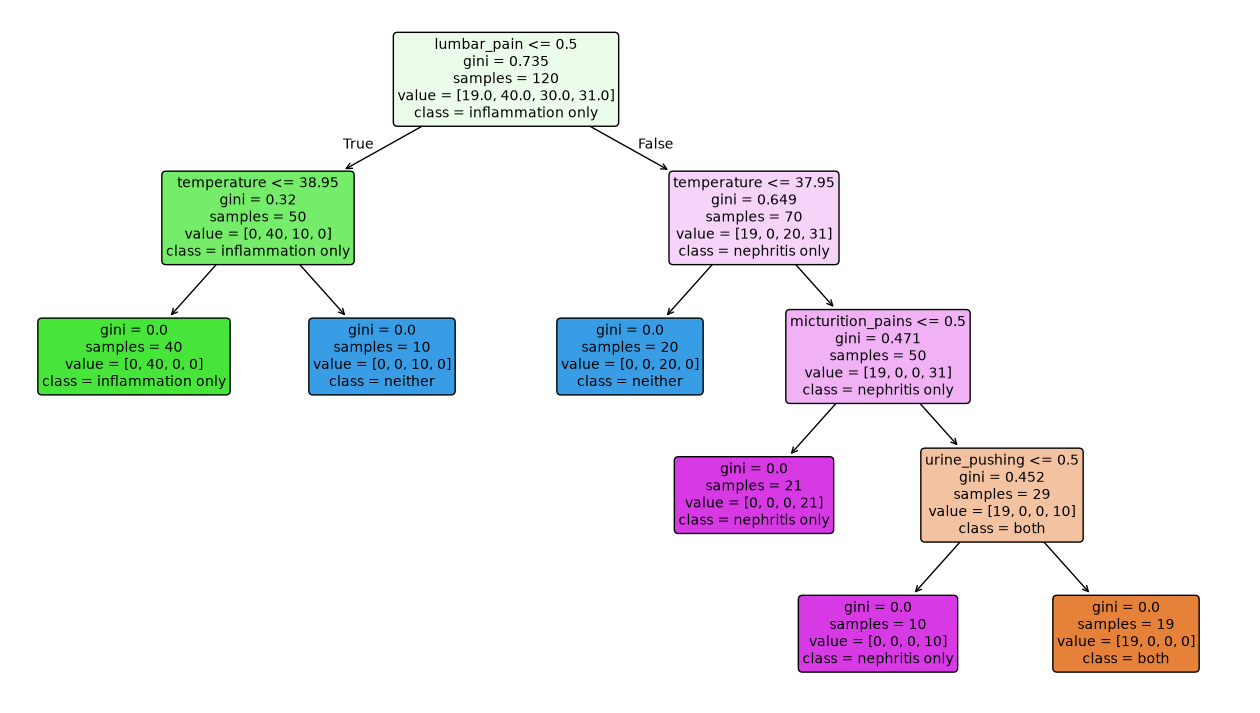

In [45]:
features = cols[:6]
x = df[features]

label_names = {
    (0, 0): "neither",
    (1, 0): "inflammation only",
    (0, 1): "nephritis only",
    (1, 1): "both",
}
y = [label_names[(b, n)] for b, n in zip(df["bladder_inflammation"], df["nephritis"])]
y = pd.Series(y, name="diagnosis")

tree = DecisionTreeClassifier(random_state=0)
tree.fit(x, y)

plt.figure(figsize=(16, 9))
plot_tree(tree, feature_names=features, class_names=tree.classes_, filled=True, rounded=True, fontsize=10)
plt.show()

### (c) Convert the decision rules

In [46]:
def tree_to_code(tree, feature_names):
	tree_ = tree.tree_
	feature_name = [
		feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
		for i in tree_.feature
	]

	def recurse(node, rule):
		if tree_.feature[node] != _tree.TREE_UNDEFINED:
			name = feature_name[node]
			threshold = tree_.threshold[node]
			recurse(tree_.children_left[node], rule + ["{} <= {:.2f}".format(name, threshold)])
			recurse(tree_.children_right[node], rule + ["{} > {:.2f}".format(name, threshold)])
		else:
			print("IF {} THEN {}".format(" AND ".join(rule), tree.classes_[np.argmax(tree_.value[node])]))

	recurse(0, [])

tree_to_code(tree, features)

IF lumbar_pain <= 0.50 AND temperature <= 38.95 THEN inflammation only
IF lumbar_pain <= 0.50 AND temperature > 38.95 THEN neither
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN both


### (d) find minimal decision tree and a set of decision rules with high interpretability

,ccp_alpha,leaves,train_accuracy,cv_accuracy
0,0.000000,6,1.000000,0.991667
1,0.098167,4,0.841667,0.858333
2,0.133333,3,0.758333,0.758333
3,0.182000,2,0.591667,0.666667
4,0.222917,1,0.333333,0.483333


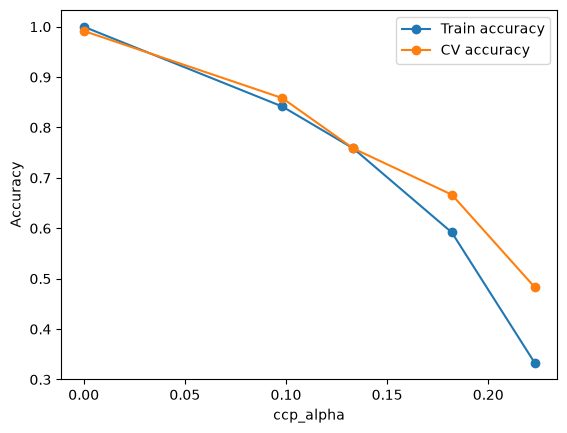

Best ccp_alpha: 0.0
Number of leaves: 6
Training accuracy: 1.0


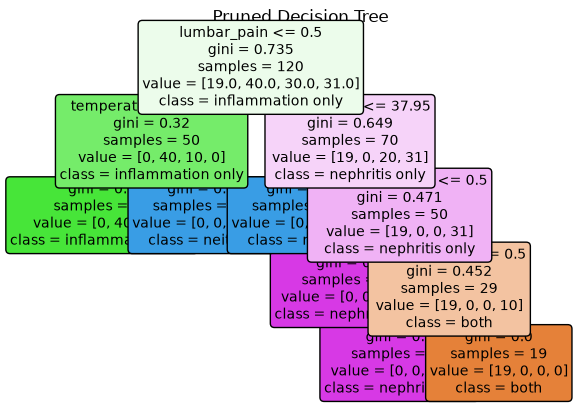

IF lumbar_pain <= 0.50 AND temperature <= 38.95 THEN inflammation only
IF lumbar_pain <= 0.50 AND temperature > 38.95 THEN neither
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN neither
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN nephritis only
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN both


In [47]:
path = tree.cost_complexity_pruning_path(x, y)
ccp_alphas = path.ccp_alphas

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for alpha in ccp_alphas:
    pruned = DecisionTreeClassifier(random_state=0, ccp_alpha=alpha)
    pruned.fit(x, y)

    cv_accuracy = cross_val_score(pruned, x, y, cv=cv).mean()
    rows.append((alpha, pruned.get_n_leaves(), pruned.score(x, y), cv_accuracy))

pruning = pd.DataFrame(rows, columns=["ccp_alpha", "leaves", "train_accuracy", "cv_accuracy"])
display(pruning)

plt.plot(pruning["ccp_alpha"], pruning["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(pruning["ccp_alpha"], pruning["cv_accuracy"], marker="o", label="CV accuracy")
plt.xlabel("ccp_alpha")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

best_cv = pruning["cv_accuracy"].max()
best_alpha = pruning.loc[pruning["cv_accuracy"] == best_cv, "ccp_alpha"].max()

pruned_tree = DecisionTreeClassifier(random_state=0, ccp_alpha=best_alpha)
pruned_tree.fit(x, y)

print("Best ccp_alpha:", best_alpha)
print("Number of leaves:", pruned_tree.get_n_leaves())
print("Training accuracy:", pruned_tree.score(x, y))

plot_tree(pruned_tree, feature_names=features, class_names=pruned_tree.classes_, filled=True, rounded=True, fontsize=10)
plt.title("Pruned Decision Tree")
plt.show()

tree_to_code(pruned_tree, features)

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [48]:
names = []
with open("communities.names") as f:
    for line in f:
        if line.startswith("@attribute"):
            names.append(line.split()[1])

crime = pd.read_csv("communities.data", header=None, names=names, na_values="?")

train = crime.iloc[:1495]
test = crime.iloc[1495:]

display(crime.head())

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [49]:
from sklearn.impute import SimpleImputer

nonpredictive = ["state", "county", "community", "communityname", "fold"]
train = train.drop(columns=nonpredictive)
test = test.drop(columns=nonpredictive)

missing = pd.concat([train, test]).isna().sum()
print(missing[missing > 0])

imputer = SimpleImputer(strategy="median")
imputer.fit(train)

train = pd.DataFrame(imputer.transform(train), columns=train.columns)
test = pd.DataFrame(imputer.transform(test), columns=test.columns)

target = "ViolentCrimesPerPop"
x_train = train.drop(columns=target)
y_train = train[target]
x_test = test.drop(columns=target)
y_test = test[target]

OtherPerCap                1
LemasSwornFT            1675
LemasSwFTPerPop         1675
LemasSwFTFieldOps       1675
LemasSwFTFieldPerPop    1675
LemasTotalReq           1675
LemasTotReqPerPop       1675
PolicReqPerOffic        1675
PolicPerPop             1675
RacialMatchCommPol      1675
PctPolicWhite           1675
PctPolicBlack           1675
PctPolicHisp            1675
PctPolicAsian           1675
PctPolicMinor           1675
OfficAssgnDrugUnits     1675
NumKindsDrugsSeiz       1675
PolicAveOTWorked        1675
PolicCars               1675
PolicOperBudg           1675
LemasPctPolicOnPatr     1675
LemasGangUnitDeploy     1675
PolicBudgPerPop         1675
dtype: int64


### (c) Plot a correlation matrix

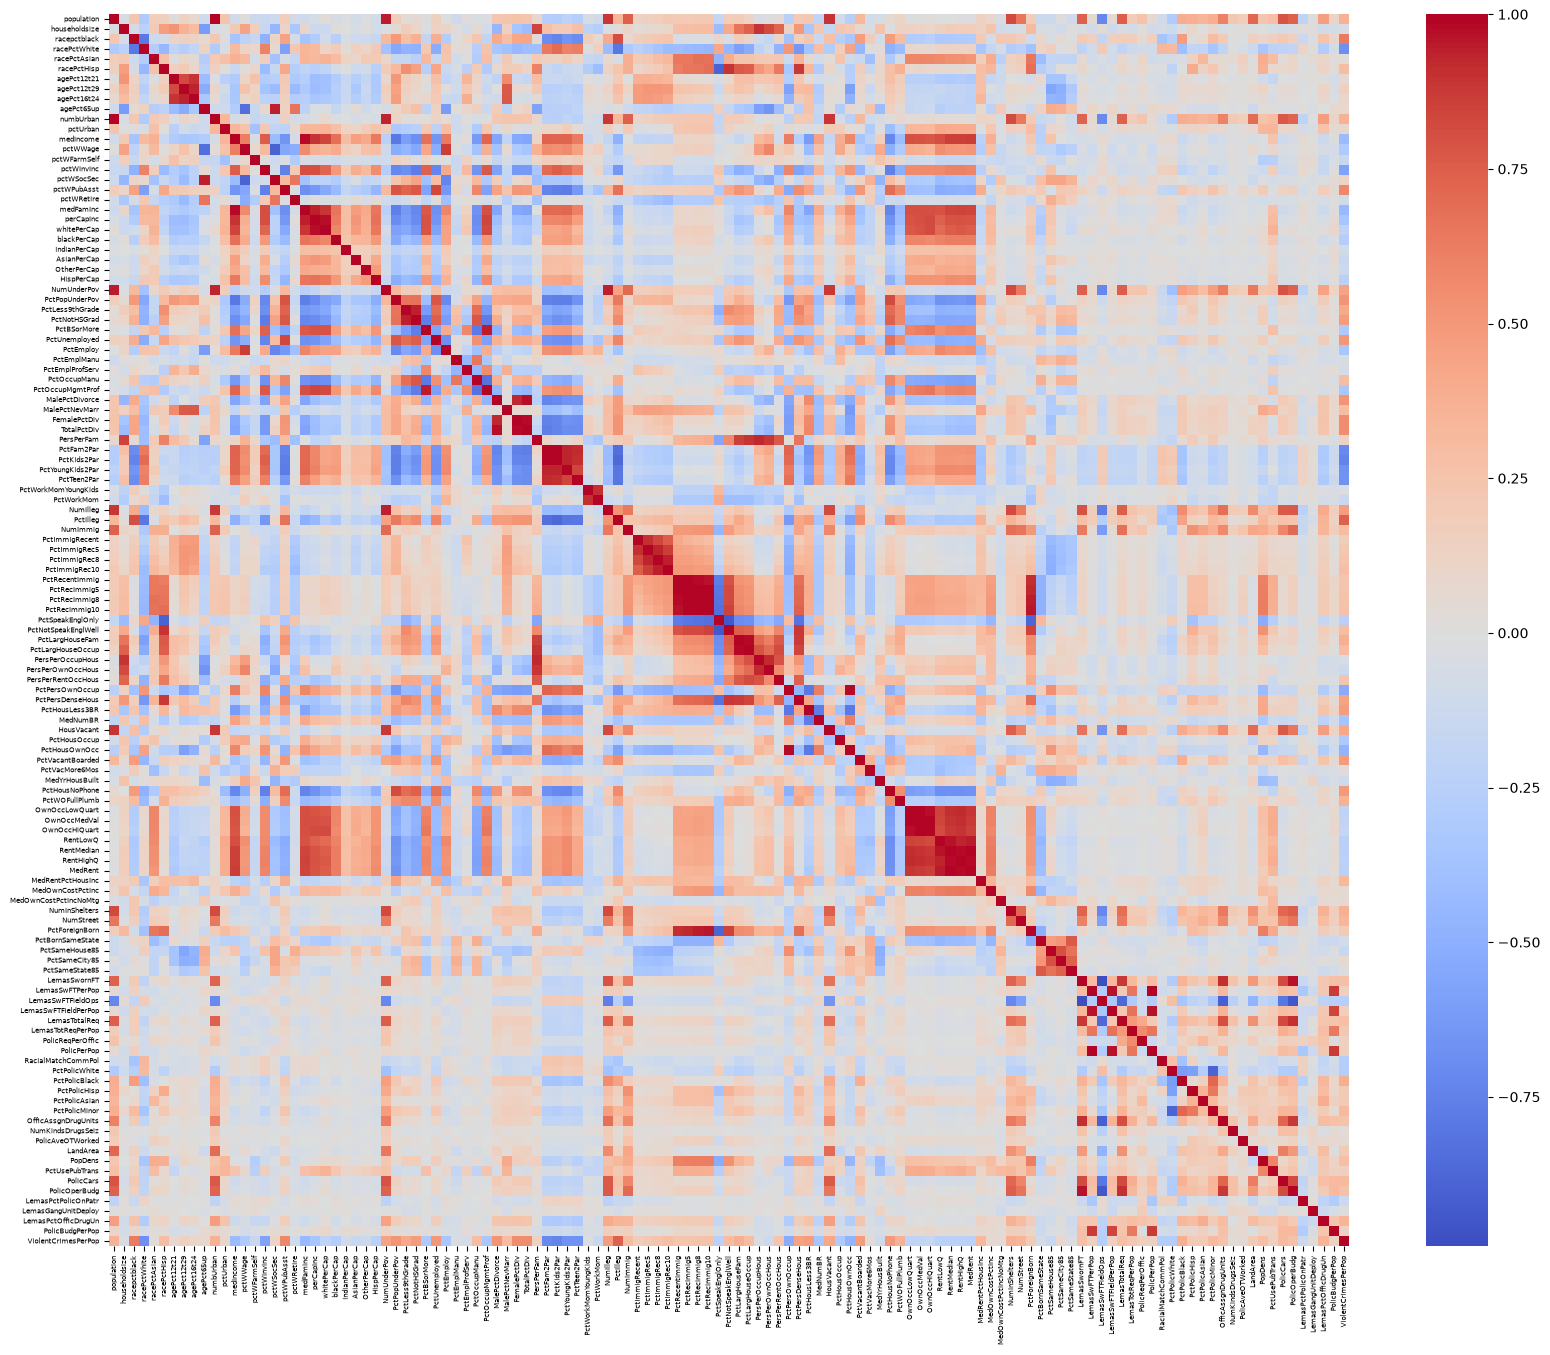

PctKids2Par        -0.738424
PctFam2Par         -0.706667
racePctWhite       -0.684770
PctYoungKids2Par   -0.666059
PctTeen2Par        -0.661582
Name: ViolentCrimesPerPop, dtype: float64
TotalPctDiv     0.552777
FemalePctDiv    0.556032
pctWPubAsst     0.574665
racepctblack    0.631264
PctIlleg        0.737957
Name: ViolentCrimesPerPop, dtype: float64


In [50]:
crime_all = pd.concat([train, test])

plt.figure(figsize=(20, 16))
sns.heatmap(crime_all.corr(), cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.show()

target_corr = crime_all.corr()[target].drop(target).sort_values()
print(target_corr.head(5))
print(target_corr.tail(5))

### (d) Calculate the Coefficient of Variation CV

In [51]:
x_all = crime_all.drop(columns=target)

cv_values = x_all.std() / x_all.mean()
cv_values = cv_values.sort_values(ascending=False)

cv_values.to_frame("CV")

,CV
PctPolicAsian,5.447835
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
...,...
NumKindsDrugsSeiz,0.143227
RacialMatchCommPol,0.126902
LemasPctPolicOnPatr,0.117807
PctPolicWhite,0.117726


### (e) Scatter plots and box plots for highest CV features

11 features with highest CV: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


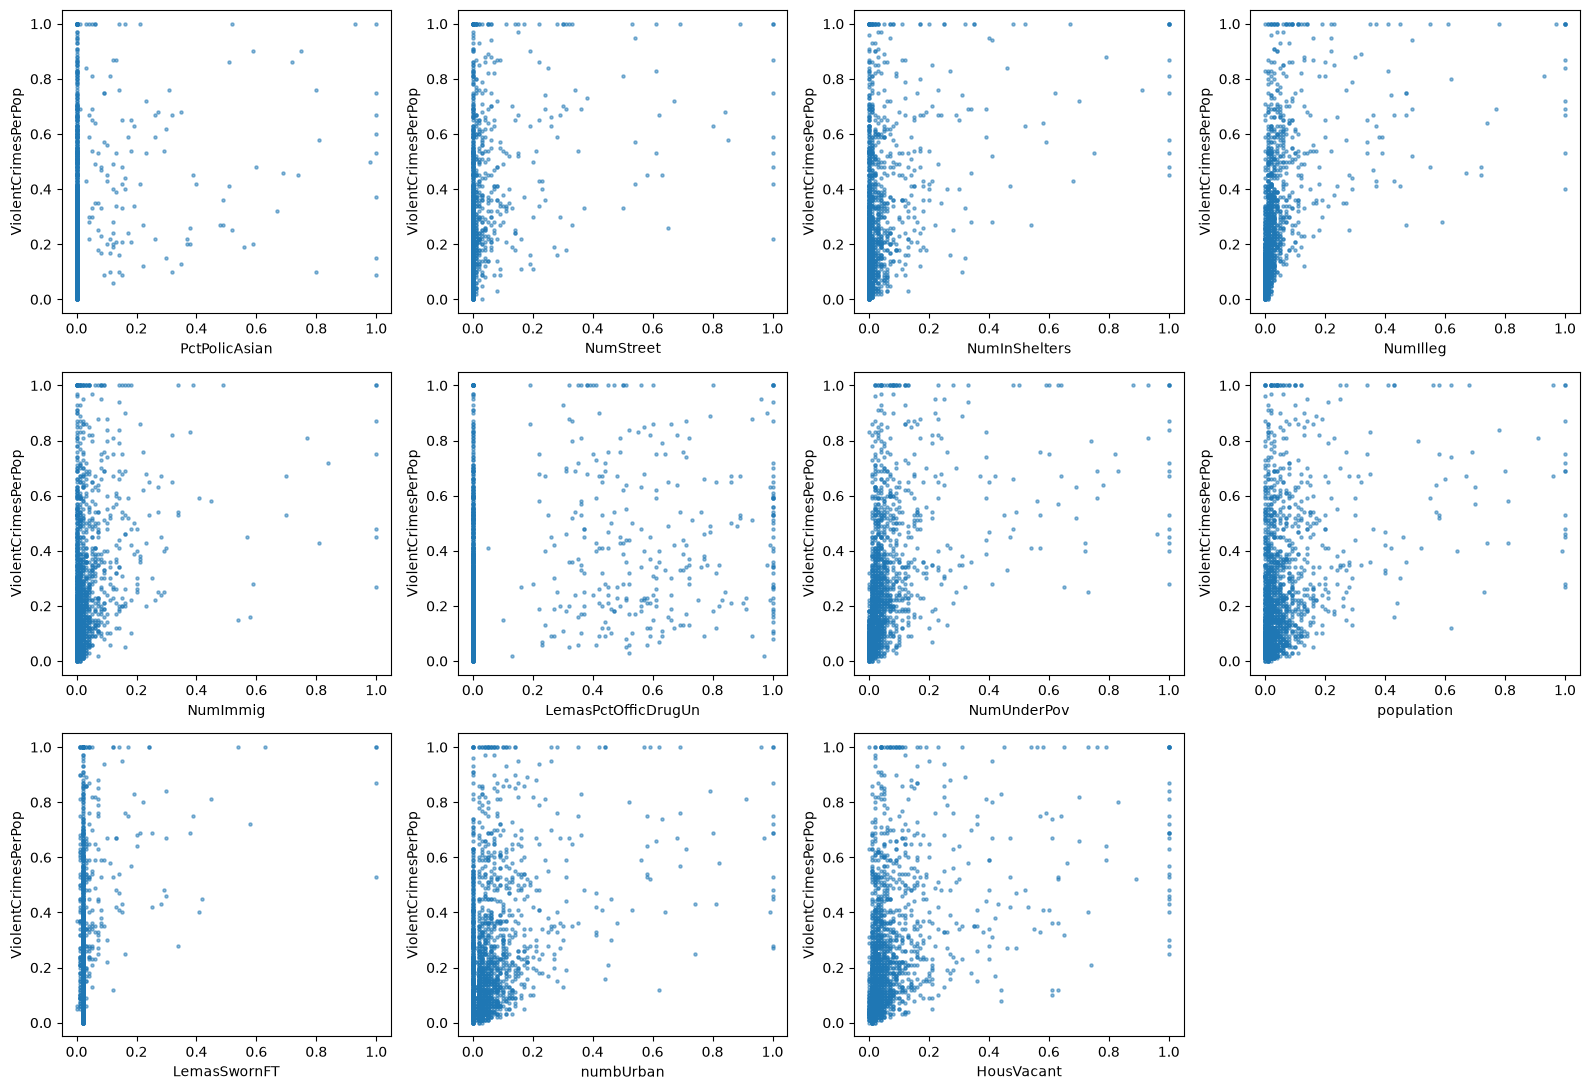

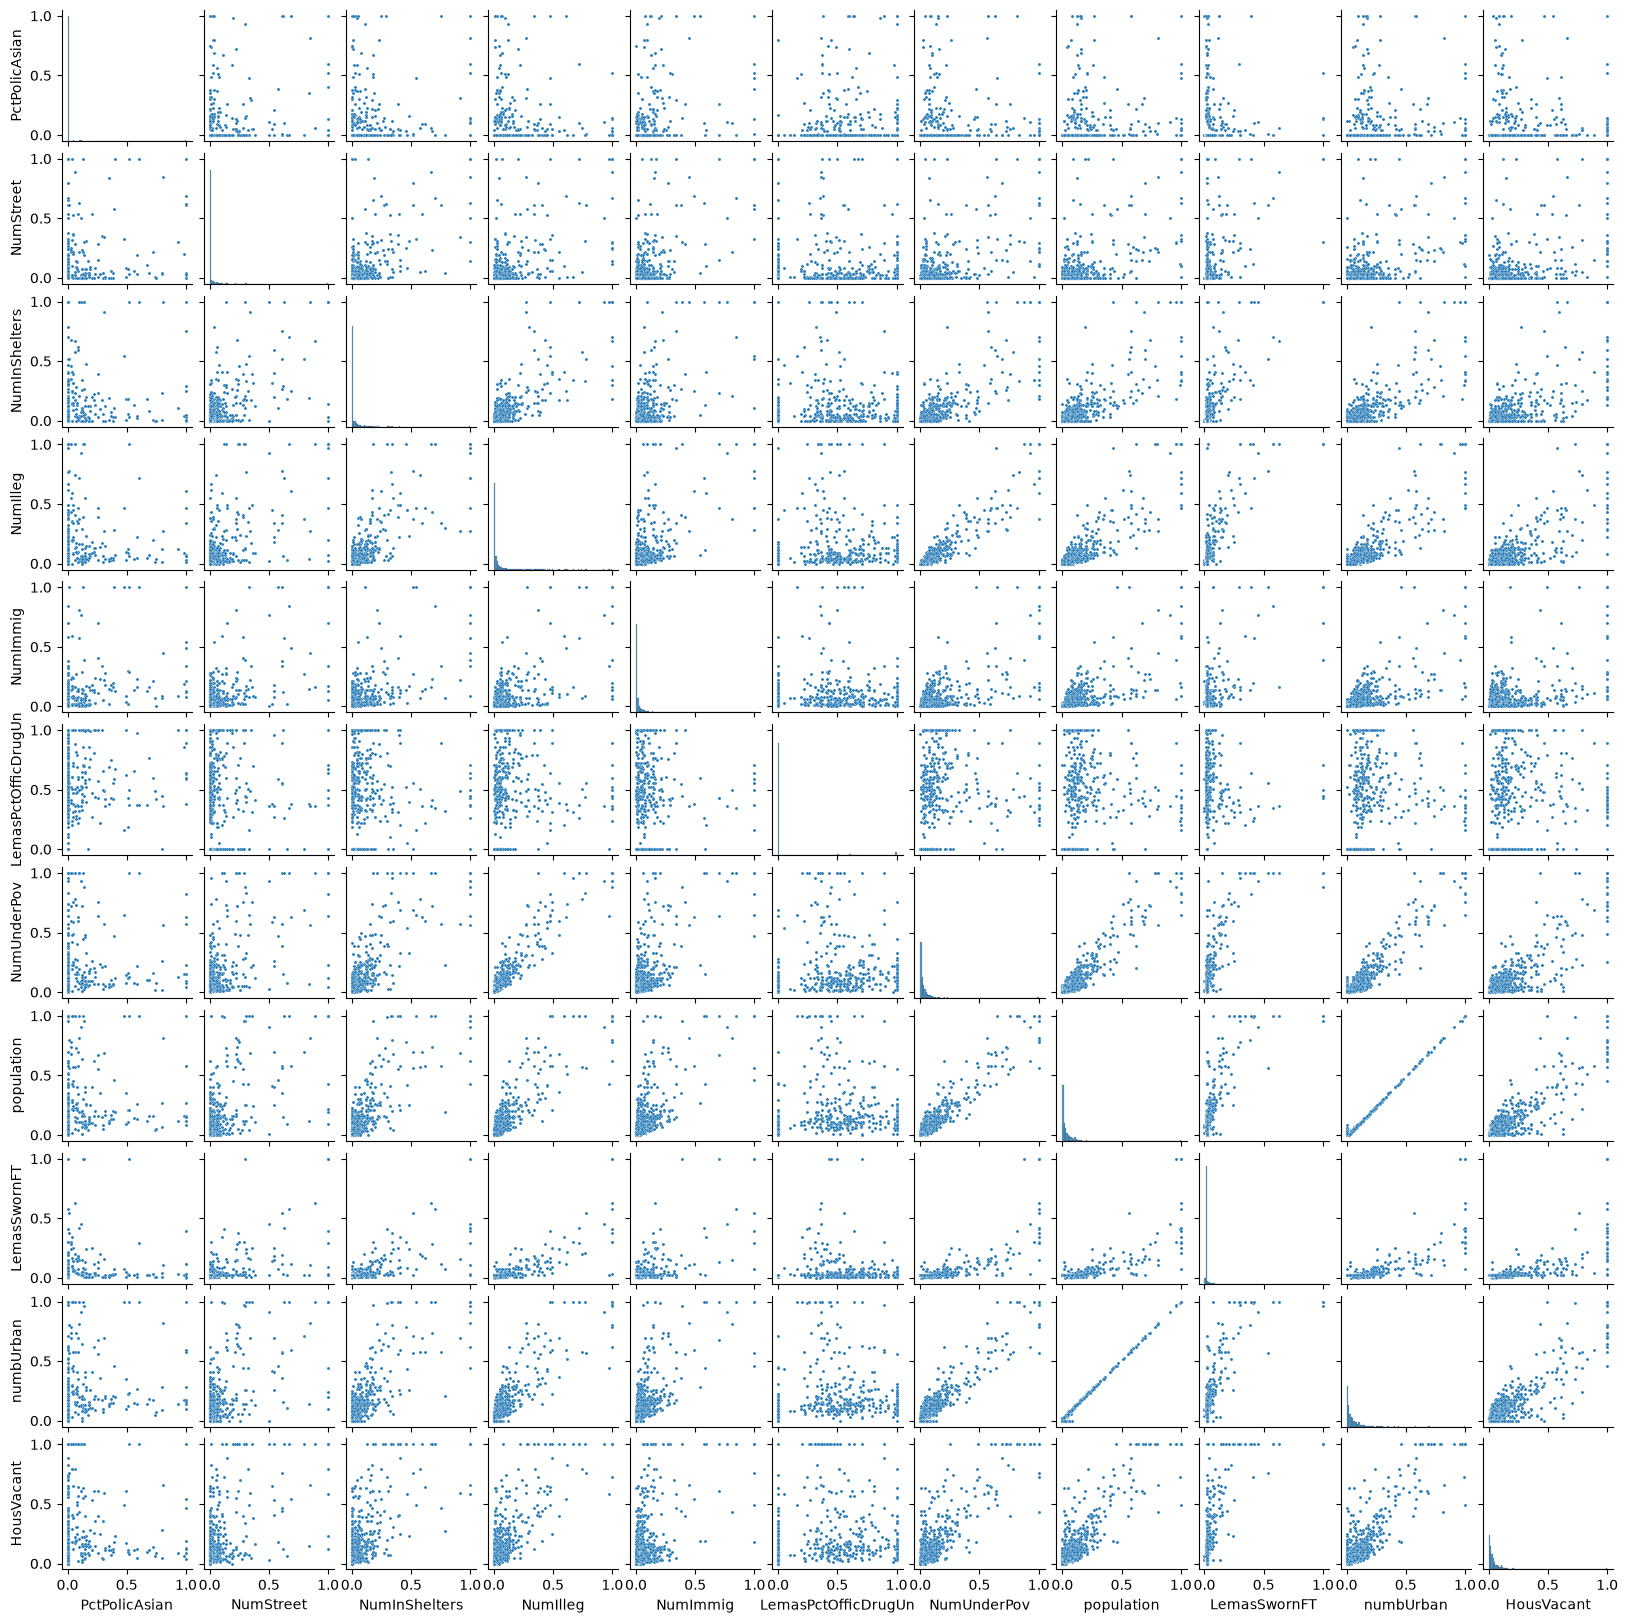

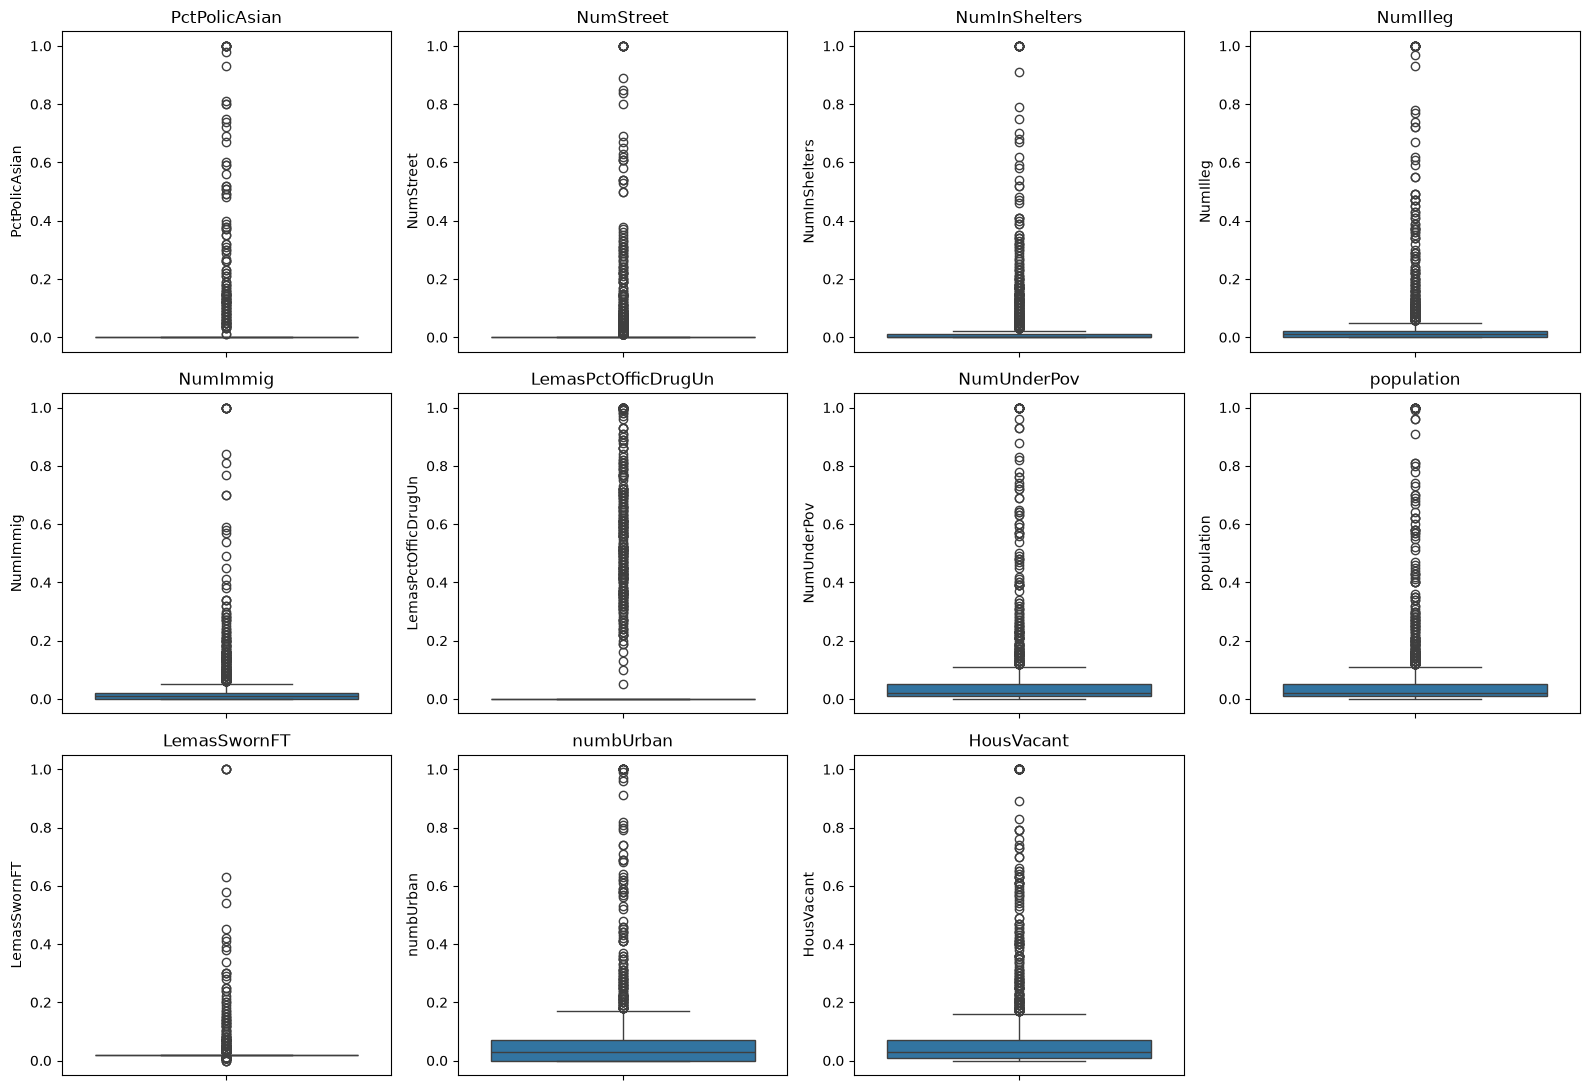

In [52]:
k = int(np.floor(np.sqrt(128)))
top_features = cv_values.index[:k].tolist()
print(k, "features with highest CV:", top_features)

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    axes[i].scatter(crime_all[feature], crime_all[target], s=5, alpha=0.5)
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel(target)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

sns.pairplot(crime_all[top_features], plot_kws={"s": 5}, height=1.5)
plt.show()

fig, axes = plt.subplots(3, 4, figsize=(16, 11))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(y=crime_all[feature], ax=axes[i])
    axes[i].set_title(feature)

axes[-1].axis("off")
plt.tight_layout()
plt.show()

We cannot tell whether these features are significant just from the scatter plots. Most of them are counts，where almost all values are close to 0 and a few large cities are outliers. Some plots show a weak positive trend with ViolentCrimesPerPop, but a scatter plot only looks at one feature at a time and gives no p-value. To check significance we need to fit a model and test the coefficients.

### (f) Fit a linear model

In [53]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

ols = LinearRegression()
ols.fit(x_train, y_train)

ols_test_mse = mean_squared_error(y_test, ols.predict(x_test))
print("Linear Regression Test MSE:", ols_test_mse)

Linear Regression Test MSE: 0.017966215426067335


### (g) Fit a ridge regression model

In [54]:
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold

kf = KFold(n_splits=10, shuffle=True, random_state=42)

ridge = RidgeCV(alphas=np.logspace(-3, 3, 100), cv=kf)
ridge.fit(x_train, y_train)

ridge_test_mse = mean_squared_error(y_test, ridge.predict(x_test))
print("Best lambda:", ridge.alpha_)
print("Ridge Test MSE:", ridge_test_mse)

Best lambda: 3.2745491628777286
Ridge Test MSE: 0.01747496536335221


### (h) Fit a LASSO model

In [55]:
lasso = LassoCV(alphas=np.logspace(-6, 0, 100), cv=kf, max_iter=100000)
lasso.fit(x_train, y_train)

lasso_test_mse = mean_squared_error(y_test, lasso.predict(x_test))
lasso_selected = x_train.columns[lasso.coef_ != 0].tolist()

print("Best lambda:", lasso.alpha_)
print("LASSO Test MSE:", lasso_test_mse)
print("Number of selected variables:", len(lasso_selected))
print(lasso_selected)

scaler = StandardScaler()
x_train_std = scaler.fit_transform(x_train)
x_test_std = scaler.transform(x_test)

lasso_std = LassoCV(alphas=np.logspace(-6, 0, 100), cv=kf, max_iter=100000)
lasso_std.fit(x_train_std, y_train)

lasso_std_test_mse = mean_squared_error(y_test, lasso_std.predict(x_test_std))
lasso_std_selected = x_train.columns[lasso_std.coef_ != 0].tolist()

print("Best lambda:", lasso_std.alpha_)
print("LASSO (standardized) Test MSE:", lasso_std_test_mse)
print("Number of selected variables:", len(lasso_std_selected))
print(lasso_std_selected)

Best lambda: 0.00011497569953977356
LASSO Test MSE: 0.017636240990904117
Number of selected variables: 74
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRecent', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg

### (i) Fit a PCR model

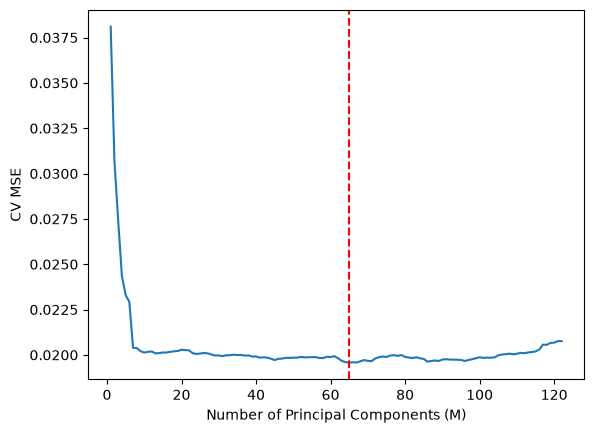

Best M: 65
PCR Test MSE: 0.018432494732573985


In [56]:
m_values = range(1, x_train.shape[1] + 1)
pcr_cv_mse = []

for m in m_values:
    pcr = make_pipeline(PCA(n_components=m), LinearRegression())
    scores = cross_val_score(pcr, x_train, y_train, cv=kf, scoring="neg_mean_squared_error")
    pcr_cv_mse.append(-scores.mean())

best_m = m_values[int(np.argmin(pcr_cv_mse))]

plt.plot(m_values, pcr_cv_mse)
plt.axvline(best_m, color="red", linestyle="--")
plt.xlabel("Number of Principal Components (M)")
plt.ylabel("CV MSE")
plt.show()

pcr = make_pipeline(PCA(n_components=best_m), LinearRegression())
pcr.fit(x_train, y_train)

pcr_test_mse = mean_squared_error(y_test, pcr.predict(x_test))
print("Best M:", best_m)
print("PCR Test MSE:", pcr_test_mse)

### (j) Fit a boosting tree

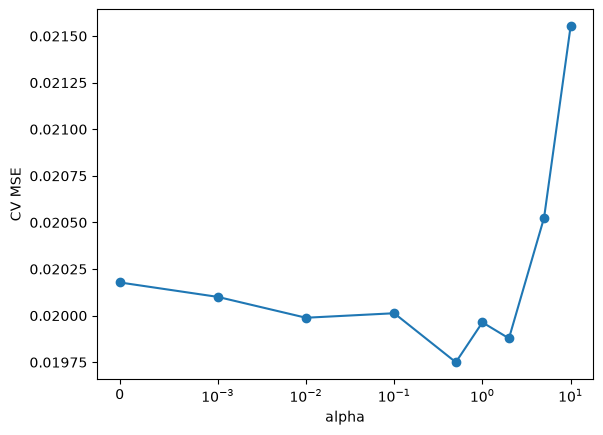

Best alpha: 0.5
XGBoost Test MSE: 0.016682024064232838


,Model,Test MSE
0,Linear Regression,0.017966
1,Ridge,0.017475
2,LASSO,0.017636
3,LASSO (standardized),0.017729
4,PCR,0.018432
5,XGBoost (L1),0.016682


In [57]:
alphas = [0, 0.001, 0.01, 0.1, 0.5, 1, 2, 5, 10]

booster = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
grid = GridSearchCV(booster, {"reg_alpha": alphas}, cv=kf, scoring="neg_mean_squared_error")
grid.fit(x_train, y_train)

xgb_cv_mse = -grid.cv_results_["mean_test_score"]

plt.plot(alphas, xgb_cv_mse, marker="o")
plt.xscale("symlog", linthresh=0.001)
plt.xlabel("alpha")
plt.ylabel("CV MSE")
plt.show()

xgb_test_mse = mean_squared_error(y_test, grid.predict(x_test))
print("Best alpha:", grid.best_params_["reg_alpha"])
print("XGBoost Test MSE:", xgb_test_mse)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge", "LASSO", "LASSO (standardized)", "PCR", "XGBoost (L1)"],
    "Test MSE": [ols_test_mse, ridge_test_mse, lasso_test_mse, lasso_std_test_mse, pcr_test_mse, xgb_test_mse],
})
results